In [ ]:
from google.colab import files
uploaded = files.upload()

import cv2
img = cv2.imread('image_name.png')

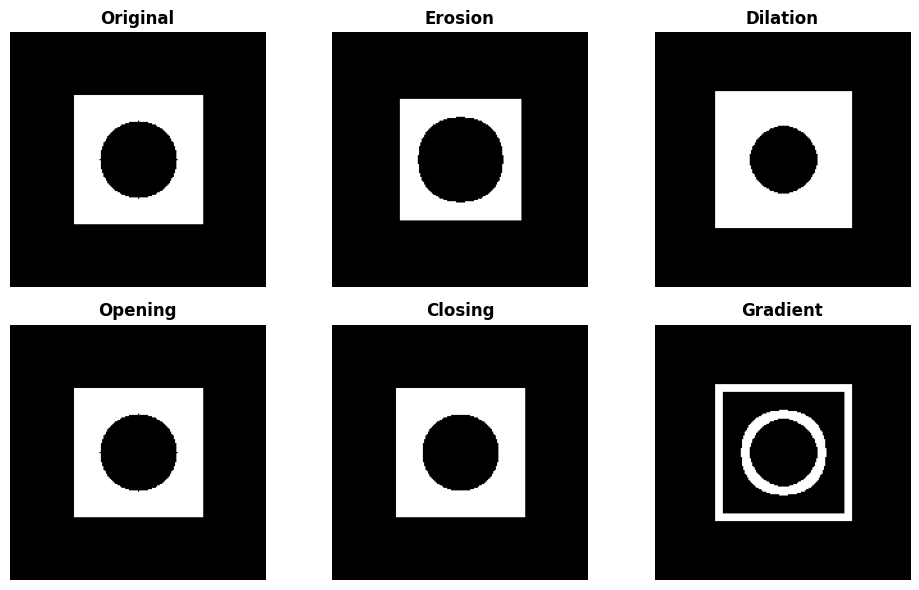

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Create base binary image (square with a circular hole)
img = np.zeros((200, 200), np.uint8)
cv2.rectangle(img, (50, 50), (150, 150), 255, -1)    # White square
cv2.circle(img, (100, 100), 30, 0, -1)               # Black hole in middle

# 2. Define structuring element/kernel
kernel = np.ones((7, 7), np.uint8)

# 3. Apply morphological operations
erosion  = cv2.erode(img, kernel, iterations=1) # Shrink white regions
dilation = cv2.dilate(img, kernel, iterations=1)  # Grow white regions
opening  = cv2.morphologyEx(img, cv2.MORPH_OPEN, kernel) # Remove small white noise
closing  = cv2.morphologyEx(img, cv2.MORPH_CLOSE, kernel) # Fill small black holes
gradient = cv2.morphologyEx(img, cv2.MORPH_GRADIENT, kernel) # Extract object boundaries


# 4. Plot results
titles = ['Original', 'Erosion', 'Dilation', 'Opening', 'Closing', 'Gradient']
images = [img, erosion, dilation, opening, closing, gradient]

plt.figure(figsize=(10, 6))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i], fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

image_path = "/content/drive/MyDrive/Computer Vision/bottles1.png"


Mounted at /content/drive


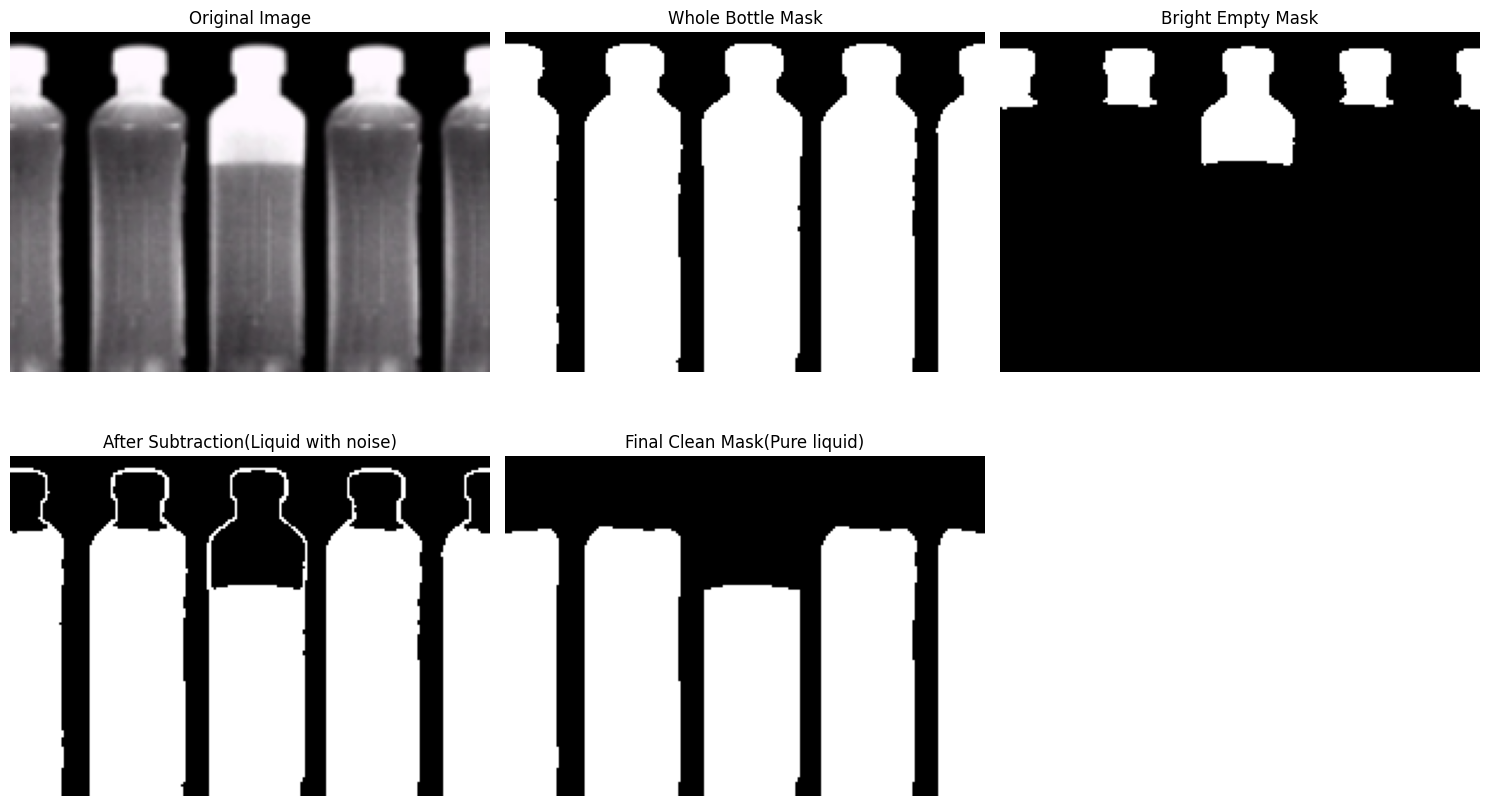

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read Image
img = cv2.imread(image_path)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 2. Generate two images with Low and High thresholds
# Low threshold: captures full bottle interior (liquid + empty upper section)
_, liquid_white = cv2.threshold(gray, 50, 255, cv2.THRESH_BINARY) #Grayscale image ko binary (pure black aur white) mask mein convert karta hai

# High threshold: captures only the bright empty upper region
_, liquid_black = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY)   #Agar {Pixel Value} > {thresh}, to output =maxval 255 / White), otherwise black.  (Thresh)binary purpose)

# 3. Minus these images (Subtract empty region)
liquid_noise = cv2.subtract(liquid_white, liquid_black)

kernel = np.ones((5, 5), np.uint8)

# 4: Remove small white noise
pure = cv2.morphologyEx(
    liquid_noise, cv2.MORPH_OPEN, kernel
)

# 5: Fill small black holes
pure = cv2.morphologyEx(
    pure, cv2.MORPH_CLOSE, kernel
)

#Display all five stages
stages = [
    img,
    liquid_white,
    liquid_black,
    liquid_noise,
    pure
]

titles = [
    "Original Image",
    "Whole Bottle Mask",
    "Bright Empty Mask",
    "After Subtraction(Liquid with noise)",
    "Final Clean Mask(Pure liquid)"
]

plt.figure(figsize=(15, 9))

for i in range(5):
    plt.subplot(2, 3, i + 1)

    if len(stages[i].shape) == 2:
        plt.imshow(stages[i], cmap="gray")
    else:
        plt.imshow(
            cv2.cvtColor(stages[i], cv2.COLOR_BGR2RGB)
        )

    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()


     BOTTLE FILL PERCENTAGES     
Bottle 1: 85.93% Filled
Bottle 2: 88.43% Filled
Bottle 3: 69.00% Filled
Bottle 4: 88.28% Filled
Bottle 5: 88.87% Filled


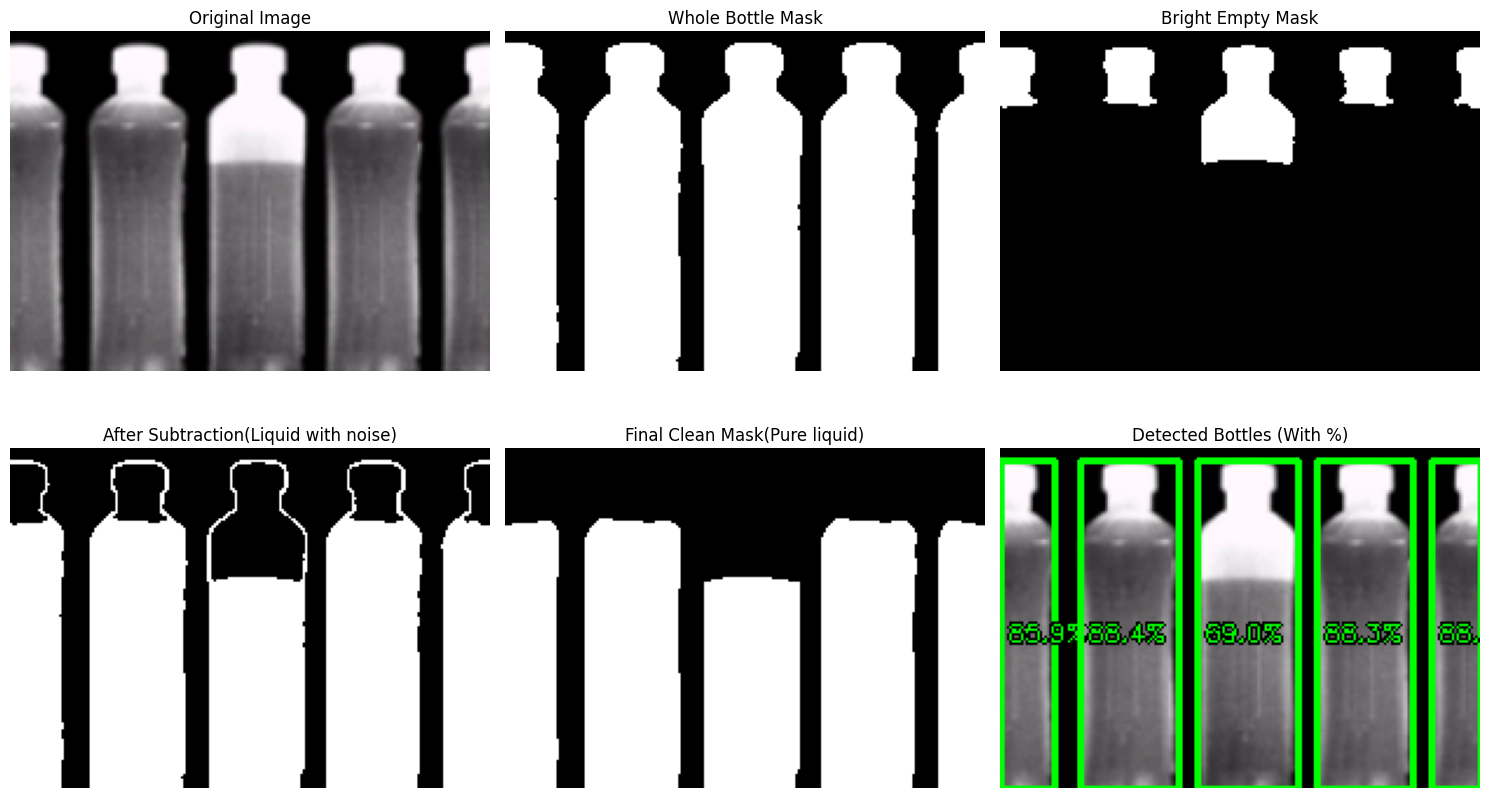

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read Image
img = cv2.imread(image_path)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 2. Generate two images with Low and High thresholds
# Low threshold: captures full bottle interior (liquid + empty upper section)
_, liquid_white = cv2.threshold(gray, 50, 255, cv2.THRESH_BINARY) #Grayscale image ko binary (pure black aur white) mask mein convert karta hai

# High threshold: captures only the bright empty upper region
_, liquid_black = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY)   #Agar {Pixel Value} > {thresh}, to output =maxval 255 / White), otherwise black.  (Thresh)binary purpose)

# 3. Minus these images (Subtract empty region)
liquid_noise = cv2.subtract(liquid_white, liquid_black)

kernel = np.ones((5, 5), np.uint8)

# 4: Remove small white noise
pure = cv2.morphologyEx(
    liquid_noise, cv2.MORPH_OPEN, kernel
)

# 5: Fill small black holes
pure = cv2.morphologyEx(
    pure, cv2.MORPH_CLOSE, kernel
)


# --- STEP 6: CALCULATE & PRINT FILL LEVEL PERCENTAGE OF EACH BOTTLE ---


# Step 6.1: liquid_white mask se saari bottles ke contours (boundaries) nikalna
# Is se image mein present har bottle alag se identify ho jayegi
contours, _ = cv2.findContours(liquid_white, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)  #outermost boundaries, remove redundant points

# Step 6.2: Bottle ke bounding boxes banana aur chotay noise dots ko filter karna
bottle_boxes = []
for cnt in contours:
    # Sirf un contours ko lena jinka area 1000 pixels se bara ho
    if cv2.contourArea(cnt) > 1000:
        x, y, w, h = cv2.boundingRect(cnt)  #finds coordonates of rectangle box along every bottle
        bottle_boxes.append((x, y, w, h))

# Step 6.3: Bottles ko Left to Right sequence mein sort karna (x-coordinate k according)
# Is se console mein Bottle 1, Bottle 2 always left to right order mein aayengi
bottle_boxes = sorted(bottle_boxes, key=lambda box: box[0])


boxed_img = img.copy()

# Step 6.4: Har bottle ke andar liquid ki percentage calculate karna
print("\n" + "="*35)
print("     BOTTLE FILL PERCENTAGES     ")
print("="*35)

for index, (x, y, w, h) in enumerate(bottle_boxes, start=1):
    # (a) Har bottle ke hissay ko dono masks se crop (slice) karna
    bottle_crop = liquid_white[y:y+h, x:x+w]  # Poori bottle ka total area (Internal chamber)
    liquid_crop = pure[y:y+h, x:x+w]          # Usi bottle ka only pure liquid wala area

    # (b) Non-zero ( White / 255) pixels count karna
    total_bottle_area = cv2.countNonZero(bottle_crop)
    actual_liquid_area = cv2.countNonZero(liquid_crop)

    # (c) percentage: (Liquid Pixels / Total Bottle Pixels) * 100
    if total_bottle_area > 0:  #To prevent division by Zero Error
        fill_percentage = (actual_liquid_area / total_bottle_area) * 100
    else:
        fill_percentage = 0.0

    print(f"Bottle {index}: {fill_percentage:.2f}% Filled")

    # Bounding box draw (Green box, line thickness = 2)
    cv2.rectangle(boxed_img, (x, y), (x + w, y + h), (0, 255, 0), 2)

    # Text ki position: bottle ke horizontally aur vertically center mein
    text = f"{fill_percentage:.1f}%"
    text_x = x + 3
    text_y = y + int(h * 0.55)

    # Chota clear text (font scale = 0.35, thickness = 1)
    # Black outline taake kisi bhi background par text highlight ho
    cv2.putText(boxed_img, text, (text_x, text_y),
                cv2.FONT_HERSHEY_SIMPLEX, 0.35, (0, 0, 0), 2)

    cv2.putText(boxed_img, text, (text_x, text_y),
                cv2.FONT_HERSHEY_SIMPLEX, 0.35, (0, 255, 0), 1)

print("="*35)

#Display all five stages
stages = [
    img,
    liquid_white,
    liquid_black,
    liquid_noise,
    pure,
    boxed_img
]

titles = [
    "Original Image",
    "Whole Bottle Mask",
    "Bright Empty Mask",
    "After Subtraction(Liquid with noise)",
    "Final Clean Mask(Pure liquid)",
    "Detected Bottles (With %)"
]

plt.figure(figsize=(15, 9))

for i in range(6):
    plt.subplot(2, 3, i + 1)

    if len(stages[i].shape) == 2:
        plt.imshow(stages[i], cmap="gray")
    else:
        plt.imshow(
            cv2.cvtColor(stages[i], cv2.COLOR_BGR2RGB)
        )

    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

Midpoint & Fill Percentage Analysis 
Bottle 1: Fill Level = 81.43% | Midpoint = (10, 87) -> FILLED
Bottle 2: Fill Level = 82.14% | Midpoint = (53, 87) -> FILLED
Bottle 3: Fill Level = 64.29% | Midpoint = (104, 99) -> LESS FILLED
Bottle 4: Fill Level = 82.14% | Midpoint = (154, 87) -> FILLED
Bottle 5: Fill Level = 81.43% | Midpoint = (194, 88) -> FILLED


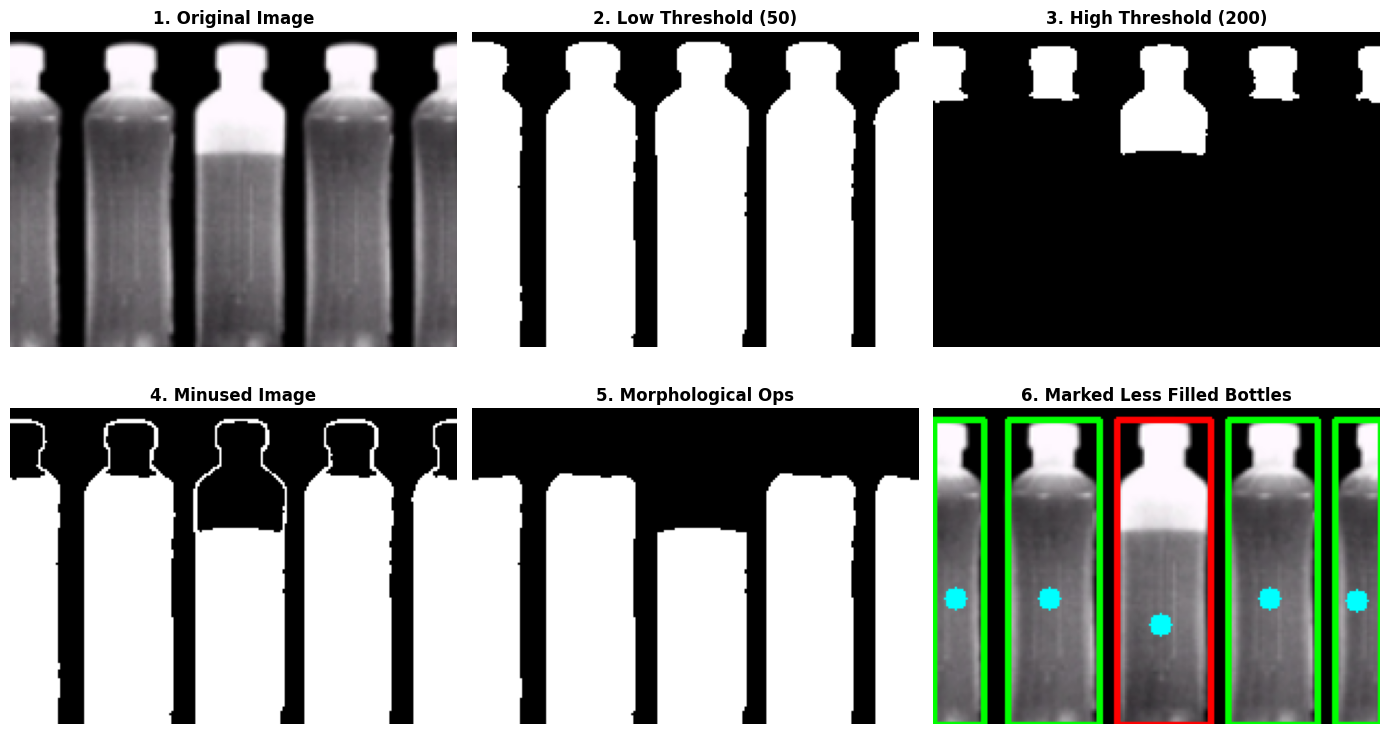

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread(image_path)

if img is None:
    raise FileNotFoundError("Image not found. Check image_path.")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

_, liquid_white = cv2.threshold(gray, 50, 255, cv2.THRESH_BINARY)  # Low threshold

_, liquid_black = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY) # High threshold

liquid_noise = cv2.subtract(liquid_white, liquid_black)

kernel = np.ones((5, 5), np.uint8)
eroded = cv2.erode(liquid_noise, kernel, iterations=1)
pure = cv2.dilate(eroded, kernel, iterations=1)                       # Pure liquid mask

contours, _ = cv2.findContours(liquid_white, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours = sorted(contours, key=lambda c: cv2.boundingRect(c)[0])  # Sort left-to-right

bottle_data = []

for idx, cnt in enumerate(contours):
    x, y, w, h = cv2.boundingRect(cnt)

    if w < 10 or h < 30:
        continue

    liquid_roi = pure[y:y+h, x:x+w]

    rows, cols = np.where(liquid_roi == 255)

    if len(rows) > 0:
        #Calculate Midpoints of liquid
        mid_row = int(y + np.mean(rows))
        mid_col = int(x + np.mean(cols))

        # Track top row where liquid starts
        top_row = y + np.min(rows)

        liquid_height = np.max(rows) - np.min(rows) + 1
        fill_percentage = (liquid_height / h) * 100

        bottle_data.append({
            'id': idx + 1,
            'bbox': (x, y, w, h),
            'midpoint': (mid_col, mid_row),
            'top_row': top_row,
            'fill_percentage': fill_percentage
        })

max_top_row = max(b['top_row'] for b in bottle_data)

output_img = img.copy()

print("Midpoint & Fill Percentage Analysis ")
for b in bottle_data:
    x, y, w, h = b['bbox']
    mid_col, mid_row = b['midpoint']
    fill_pct = b['fill_percentage']

    # Bottle with top_row significantly below others is less filled
    is_less_filled = (b['top_row'] >= max_top_row - 15)

    color = (0, 0, 255) if is_less_filled else (0, 255, 0)
    status = "LESS FILLED" if is_less_filled else "FILLED"

    # Draw Bounding Box & Midpoint
    cv2.rectangle(output_img, (x, y), (x + w, y + h), color, 2)
    cv2.circle(output_img, (mid_col, mid_row), 5, (255, 255, 0), -1) # Cyan midpoint dot

    cv2.putText(output_img, f"B{b['id']}: {fill_pct:.1f}%", (x, y - 25),
                cv2.FONT_HERSHEY_SIMPLEX, 0.4, color, 1)
    cv2.putText(output_img, f"{status}", (x, y - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.4, color, 1)

    print(f"Bottle {b['id']}: Fill Level = {fill_pct:.2f}% | Midpoint = {b['midpoint']} -> {status}")

# 7. Visualizing 5 Processing Stages + Final Marking Result
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

axes[0, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title('1. Original Image', fontweight='bold')

axes[0, 1].imshow(liquid_white, cmap='gray')
axes[0, 1].set_title('2. Low Threshold (50)', fontweight='bold')

axes[0, 2].imshow(liquid_black, cmap='gray')
axes[0, 2].set_title('3. High Threshold (200)', fontweight='bold')

axes[1, 0].imshow(liquid_noise, cmap='gray')
axes[1, 0].set_title('4. Minused Image', fontweight='bold')

axes[1, 1].imshow(pure, cmap='gray')
axes[1, 1].set_title('5. Morphological Ops', fontweight='bold')

axes[1, 2].imshow(cv2.cvtColor(output_img, cv2.COLOR_BGR2RGB))
axes[1, 2].set_title('6. Marked Less Filled Bottles', fontweight='bold')

for ax in axes.ravel():
    ax.axis('off')

plt.tight_layout()
plt.show()

Area: 9800.00, Perimeter: 477.99, Circularity: 0.539
Area: 19600.00, Perimeter: 560.00, Circularity: 0.785
Area: 15176.00, Perimeter: 461.59, Circularity: 0.895


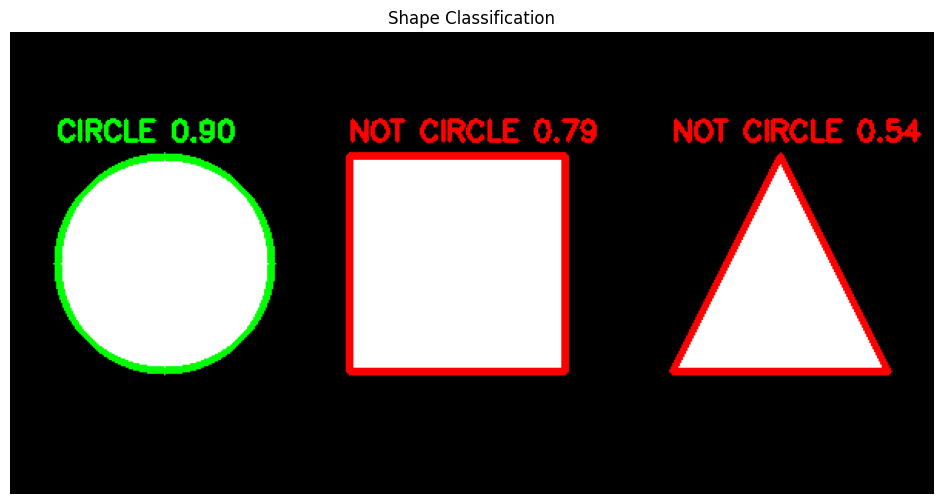

In [ ]:

# TASK 4: SHAPE CLASSIFICATION BY CIRCULARITY
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Create a black canvas
canvas = np.zeros((300, 600, 3), dtype=np.uint8)

# Step 2: Draw a circle
cv2.circle(
    canvas, (100, 150), 70,
    (255, 255, 255), -1
)

# Step 3: Draw a square
cv2.rectangle(
    canvas, (220, 80), (360, 220),
    (255, 255, 255), -1
)

# Step 4: Draw a triangle
pts = np.array(
    [[500, 80], [430, 220], [570, 220]],
    np.int32
)

cv2.fillPoly(canvas, [pts], (255, 255, 255))

# Step 5: Convert to grayscale
gray = cv2.cvtColor(
    canvas, cv2.COLOR_BGR2GRAY
)

# Step 6: Apply Otsu thresholding
_, thresh = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Step 7: Find contours
contours, _ = cv2.findContours(
    thresh,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Step 8: Analyze every contour
for c in contours:

    area = cv2.contourArea(c)
    perimeter = cv2.arcLength(c, True)

    if perimeter == 0:
        continue

    circularity = (
        4 * np.pi * area / (perimeter ** 2)
    )

    x, y, w, h = cv2.boundingRect(c)

    # Classify based on threshold
    is_round = circularity > 0.8

    if is_round:
        color = (0, 255, 0)
        label = "CIRCLE"
    else:
        color = (0, 0, 255)
        label = "NOT CIRCLE"

    # Draw contour
    cv2.drawContours(
        canvas, [c], -1, color, 3
    )

    # Add label
    cv2.putText(
        canvas,
        f"{label} {circularity:.2f}",
        (x, max(y - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        color,
        2
    )

    print(
        f"Area: {area:.2f}, "
        f"Perimeter: {perimeter:.2f}, "
        f"Circularity: {circularity:.3f}"
    )


plt.figure(figsize=(12, 6))

plt.imshow(
    cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)
)

plt.title("Shape Classification")
plt.axis("off")
plt.show()

In [ ]:
image_path5 = "/content/drive/MyDrive/Computer Vision/apples.png"

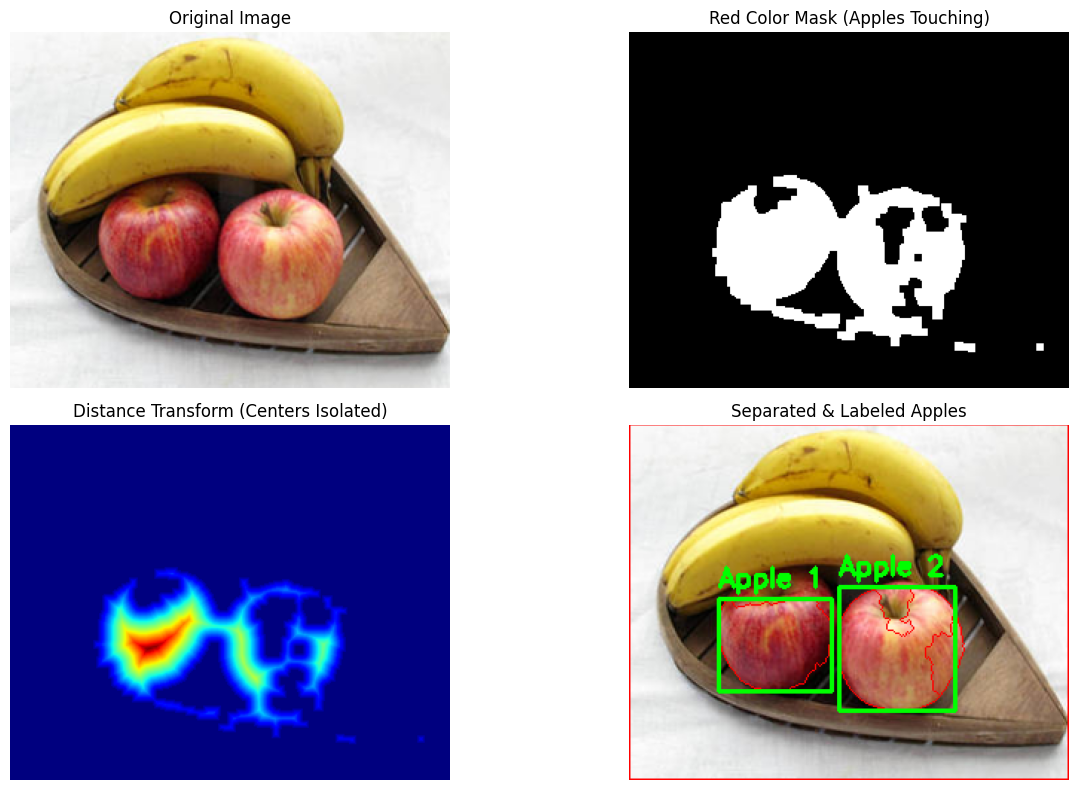

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read Image
img = cv2.imread(image_path5)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 2. Convert to HSV to extract RED color (Apples)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

# Red color wraps around 0 and 180 in OpenCV HSV, so we define two ranges
lower_red1 = np.array([0, 70, 50])
upper_red1 = np.array([10, 255, 255])
lower_red2 = np.array([160, 70, 50])
upper_red2 = np.array([180, 255, 255])

mask1 = cv2.inRange(hsv, lower_red1, upper_red1)
mask2 = cv2.inRange(hsv, lower_red2, upper_red2)
apple_mask = cv2.bitwise_or(mask1, mask2)

# Morphological Closing to fill small reflections/holes inside apples
kernel = np.ones((5, 5), np.uint8)
apple_mask = cv2.morphologyEx(apple_mask, cv2.MORPH_CLOSE, kernel)
apple_mask = cv2.morphologyEx(apple_mask, cv2.MORPH_OPEN, kernel)

# 3. Distance Transform (Separate touching region)
dist_transform = cv2.distanceTransform(apple_mask, cv2.DIST_L2, 5)

# Threshold distance transform to find the sure foreground (center of each apple)
# Peak value ka 45-55% le kar dono apples ke alag centers isolate ho jatay hain
_, sure_fg = cv2.threshold(dist_transform, 0.45 * dist_transform.max(), 255, cv2.THRESH_BINARY)
sure_fg = np.uint8(sure_fg)

# Dilate sure background
sure_bg = cv2.dilate(apple_mask, kernel, iterations=3)

# Unknown region (boundary area where apples touch)
unknown = cv2.subtract(sure_bg, sure_fg)

# 4. Marker labelling for Watershed
_, markers = cv2.connectedComponents(sure_fg)
# Watershed markers mein background 1 hona chahiye, unknown 0
markers = markers + 1
markers[unknown == 255] = 0

# Apply Watershed
markers = cv2.watershed(img, markers)

# 5. Draw Results & Label Each Apple
output_img = img.copy()

# Watershed boundary ko -1 mark karta hai (jahan apples split huay)
output_img[markers == -1] = [0, 0, 255]  # Red cut line

# Har marker label (excluding 1 which is background) ke bounding box aur labels
unique_labels = np.unique(markers)
apple_id = 1

for label in unique_labels:
    if label <= 1:  # 0 is boundary, 1 is background
        continue

    # Har apple ka individual binary mask
    label_mask = np.uint8(markers == label) * 255
    contours, _ = cv2.findContours(label_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if contours:
        cnt = max(contours, key=cv2.contourArea)
        if cv2.contourArea(cnt) > 2000:  # Ignore tiny artifacts
            x, y, w, h = cv2.boundingRect(cnt)

            # Green Bounding Box
            cv2.rectangle(output_img, (x, y), (x + w, y + h), (0, 255, 0), 2)

            # Label Text (Apple 1, Apple 2)
            label_text = f"Apple {apple_id}"
            cv2.putText(output_img, label_text, (x, y - 8),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
            apple_id += 1

# 6. Display Pipeline
plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(apple_mask, cmap="gray")
plt.title("Red Color Mask (Apples Touching)")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(dist_transform, cmap="jet")
plt.title("Distance Transform (Centers Isolated)")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(cv2.cvtColor(output_img, cv2.COLOR_BGR2RGB))
plt.title("Separated & Labeled Apples")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
image_path5 = "/content/drive/MyDrive/Computer Vision/apples.png"

Detected: Apple 1 | Area: 1952.50
Detected: Apple 2 | Area: 5415.00


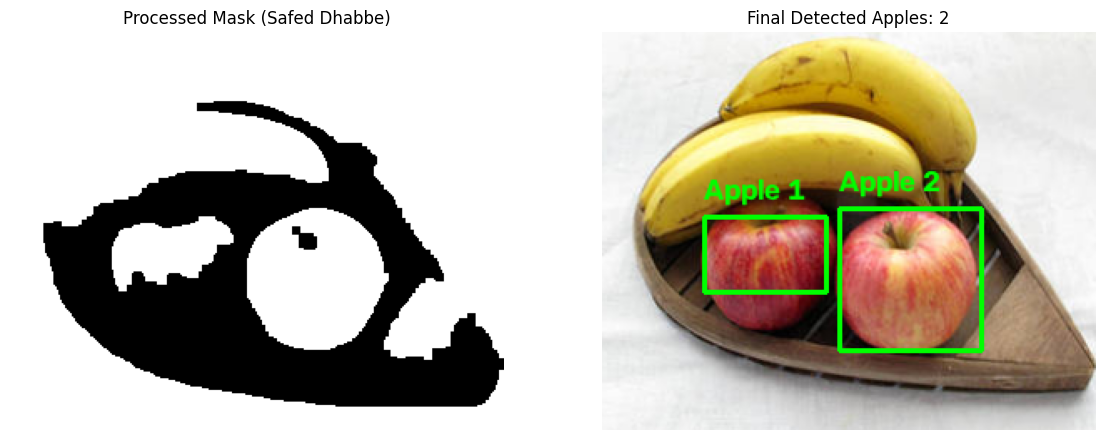

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Load image
img = cv2.imread(image_path5)

if img is None:
    print("Error: Image load nahi hui.")
else:
    # Step 2: Split BGR and take Red channel
    b, g, r = cv2.split(img)

    # Step 3: Thresholding
    _, thresh = cv2.threshold(r, 190, 255, cv2.THRESH_BINARY)

    # Step 4: Morphological Operations
    kernel = np.ones((5, 5), np.uint8)
    thresh_closed = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)
    processed_mask = cv2.morphologyEx(thresh_closed, cv2.MORPH_OPEN, kernel)

    # Step 5: Find Contours
    contours, _ = cv2.findContours(
        processed_mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    output_img = img.copy()
    apple_count = 0

    # Step 6: Loop through contours
    for c in contours:
        area = cv2.contourArea(c)

        # Strict Area Filter: Sirf apple ke size ke contours allow honge (Tray/Background reject ho jayega)
        if 800 < area < 15000:
            apple_count += 1

            x, y, w, h = cv2.boundingRect(c)

            # Green box draw karna
            cv2.rectangle(output_img, (x, y), (x + w, y + h), (0, 255, 0), 2)

            # Label text
            label = f"Apple {apple_count}"
            cv2.putText(
                output_img,
                label,
                (x, max(y - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 255, 0), 2
            )

            print(f"Detected: {label} | Area: {area:.2f}")
# Step 7: Display both Processed Mask and Final Output side-by-side
    plt.figure(figsize=(14, 6))

    # 1st Subplot: Processed Mask (Safed dhabbe / Binary Image)
    plt.subplot(1, 2, 1)
    plt.imshow(processed_mask, cmap='gray')
    plt.title("Processed Mask (Safed Dhabbe)")
    plt.axis("off")

    # 2nd Subplot: Final Output with Green Boxes
    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(output_img, cv2.COLOR_BGR2RGB))
    plt.title(f"Final Detected Apples: {apple_count}")
    plt.axis("off")

    plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
image_path5 = "/content/drive/MyDrive/Computer Vision/apples.png"

Number of apples: 2


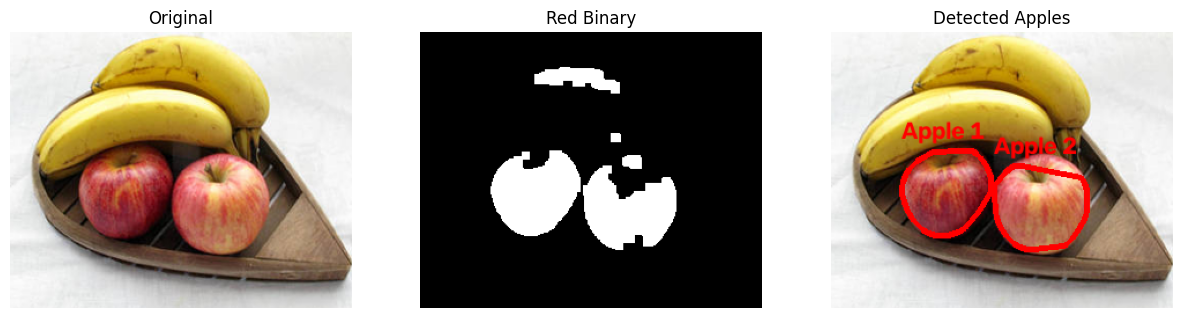

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread(image_path5)
blue, green, red = cv2.split(img)

binary = cv2.threshold(cv2.subtract(red, green), 40, 255, cv2.THRESH_BINARY)[1]

kernel = np.ones((5,5), np.uint8)
binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

binary = cv2.erode(binary, np.ones((3,3), np.uint8), iterations=5)
binary = cv2.dilate(binary, np.ones((3,3), np.uint8), iterations=3)

contours, _ = cv2.findContours(
    binary,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)
contours = sorted(contours, key=lambda c: cv2.boundingRect(c)[0])

result = img.copy()
apple_count = 0

for contour in contours:
    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)

    if perimeter == 0:
        continue

    circularity = (4 * np.pi * area) / (perimeter * perimeter)

    # Bounding rectangle nikalna width aur height check karne ke liye
    x, y, w, h = cv2.boundingRect(contour)
    aspect_ratio = float(w) / h if h > 0 else 0

    # --- BALANCED CONDITION ---
    # 1. Area > 800
    # 2. Circularity > 0.35 (Apples ke liye it kafi hai)
    # 3. Aspect Ratio check: Banana bohot lamba hota hai (w/h ratio 1.5 se zyada ya kam),
    #    jabke apple square ke qareeb hota hai (0.6 se 1.8 ke darmiyan)
    if area > 800 and circularity > 0.35 and (0.6 <= aspect_ratio <= 1.8):
        contour = cv2.convexHull(contour)


        x, y, w, h = cv2.boundingRect(contour)    # Dobara rect nikalna convex hull ke baad
        apple_count += 1

        cv2.drawContours(
            result,
            [contour],
            -1,
            (0, 0, 255),
            3
        )

        cv2.putText(
            result,
            "Apple " + str(apple_count),
            (x, y - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 0, 255),
            2
        )

print("Number of apples:", apple_count)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary, cmap="gray")
plt.title("Red Binary")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB)=)
plt.title("Detected Apples")
plt.axis("off")

plt.show()